#BIL485 Ödev-1: MNIST Veri Setiyle MLP Tabanlı El Yazısı Rakam Tanıma

**Hazırlayan: Elif Naz Üçkardeş-25120205047**

##**Amaç:**
Bu projeyi hazırlama amacımız MNIST veri setini kullanarak sıfırdan bir MLP modeli geliştirip modelin kendi hazırladığımız gerçek hayat el yazıları üzerindeki başarısını test etmek.

**Proje kapsamında CNN kullanılmamıştır.**


In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt
import numpy as np
import time
import cv2

##**Preprocessing(Ön İşleme):**

In [3]:
(train_images, train_labels), (test_images,test_labels) = mnist.load_data();

#reshaping:
train_images= train_images.reshape((60000, 28*28));
test_images=test_images.reshape((10000, 28*28));

#normalization:
train_images=train_images.astype("float32")/255;
test_images=test_images.astype("float32")/255;

#for validation:
val_images=train_images[:10000]
val_labels=train_labels[:10000]

#for training:
part_train_images= train_images[10000:]
part_train_labels=train_labels[10000:]

#for control:
print("egitim veri boyutu: ", part_train_images.shape);
print("validation veri boyutu: ", val_images.shape);
print("test veri boyutu: ",test_images.shape);

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
egitim veri boyutu:  (50000, 784)
validation veri boyutu:  (10000, 784)
test veri boyutu:  (10000, 784)


##**MLP Mimari:**

In [4]:
#mimari:
model=models.Sequential([
    layers.Input(shape=(28*28,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
]);

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
              metrics=['accuracy']);
model.summary();

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

##**Eğitim:**

In [5]:
start_time=time.time();

gecmis=model.fit(part_train_images, part_train_labels, epochs=15, batch_size=128,
                      validation_data=(val_images, val_labels));

end_time=time.time();

#süre hesap:
egitim_sure=end_time - start_time;

print("Egitim Bitti");
print(f"Egitim Suresi: {egitim_sure:.2f} saniye");

Epoch 1/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8944 - loss: 0.3680 - val_accuracy: 0.9476 - val_loss: 0.1818
Epoch 2/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9567 - loss: 0.1484 - val_accuracy: 0.9600 - val_loss: 0.1357
Epoch 3/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9690 - loss: 0.1038 - val_accuracy: 0.9687 - val_loss: 0.1046
Epoch 4/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9773 - loss: 0.0767 - val_accuracy: 0.9707 - val_loss: 0.0942
Epoch 5/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9813 - loss: 0.0616 - val_accuracy: 0.9719 - val_loss: 0.0903
Epoch 6/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9857 - loss: 0.0471 - val_accuracy: 0.9750 - val_loss: 0.0846
Epoch 7/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9887 - loss: 0.0374 - val_accuracy: 0.9754 - val_loss: 0.0868
Epoch 8/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9908 - loss: 0.0310 - val_accuracy: 0

#**Grafikler:**

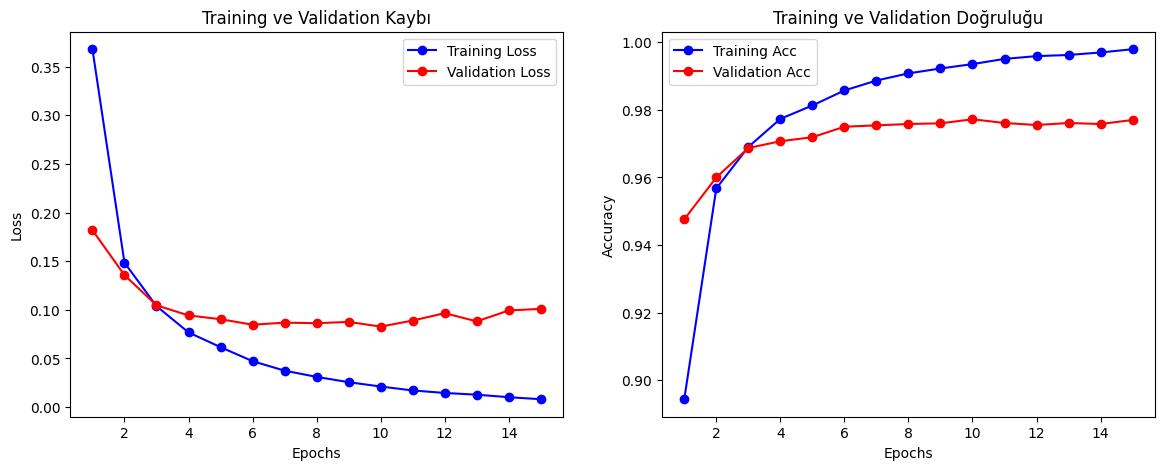

Test Verisi Değerlendirme
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9771 - loss: 0.0992
Test Accuracy: % 97.71
Test Loss: 0.0992


In [6]:
acc=gecmis.history['accuracy']
val_acc=gecmis.history['val_accuracy']
loss=gecmis.history['loss']
val_loss=gecmis.history['val_loss']

epochs= range(1, len(acc)+1)

plt.figure(figsize=(14,5));

#Loss Grafiği:
plt.subplot(1,2,1);

plt.plot(epochs, loss, 'bo-', label='Training Loss');
plt.plot(epochs, val_loss, 'ro-', label='Validation Loss');
plt.title('Training ve Validation Kaybı');
plt.xlabel('Epochs');
plt.ylabel('Loss');
plt.legend();

#Accuracy Grafiği:
plt.subplot(1,2,2);

plt.plot(epochs, acc, 'bo-', label='Training Acc');
plt.plot(epochs, val_acc, 'ro-', label='Validation Acc');
plt.title('Training ve Validation Doğruluğu');
plt.xlabel('Epochs');
plt.ylabel('Accuracy');
plt.legend();

plt.show();

#Test:

print("Test Verisi Değerlendirme");
test_loss, test_acc = model.evaluate(test_images, test_labels);
print(f"Test Accuracy: % {test_acc *100:.2f}");
print(f"Test Loss: {test_loss:.4f}");

##**Kendi Oluşturduğum Görüntülerle Test:**

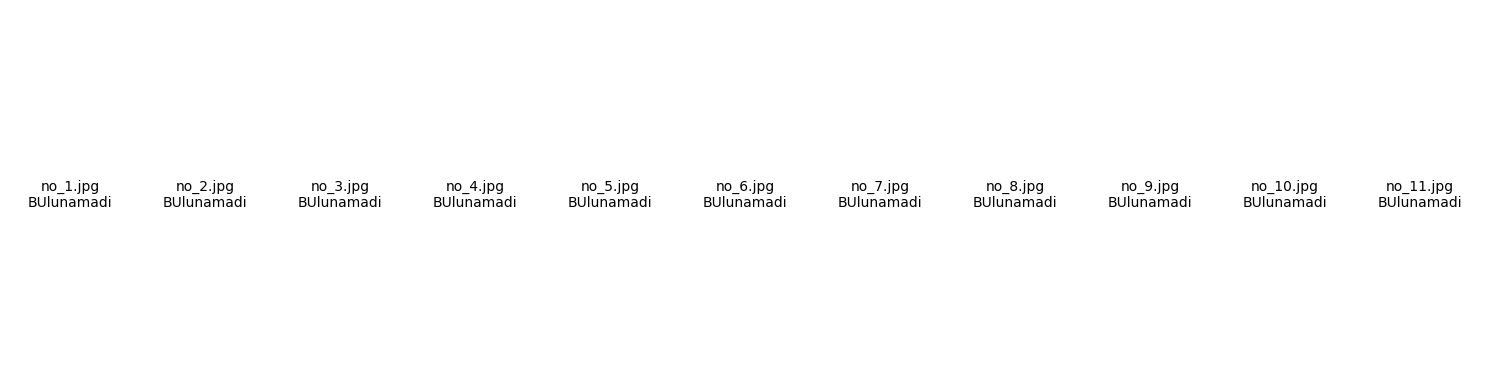


Gerçek Öğrenci No: 25120205047
Modelin Okuduğu No: ???????????


In [7]:
def image_hazirlik(image_path):
  img= cv2.imread(image_path, cv2.IMREAD_GRAYSCALE);

  if img is None:
    return None,None

  #boyut ve renk ayarlamalari
  img=cv2.resize(img, (28,28)); #resize edilmis versiyon
  img_inverted=cv2.bitwise_not(img);

  #normalization ve vektor yapma
  img=img_inverted.astype("float32")/255.0; #normalize edilmis versiyon
  img_flat= img.reshape(1, 28*28);

  return img_flat, img_inverted;


my_no="25120205047";
num_sayisi= len(my_no);

plt.figure(figsize=(15,4));
tahmin_no="";

for i in range(num_sayisi):

  dosya_adi=f"no_{i+1}.jpg";
  gercek_num= my_no[i];

  my_num_flat, processed_img=image_hazirlik(dosya_adi);

  plt.subplot(1, num_sayisi, i+1);

  if my_num_flat is not None:
    prediction= model.predict(my_num_flat, verbose=0);
    predicted_class= np.argmax(prediction);
    confidence= np.max(prediction)*100;

    tahmin_no += str(predicted_class);

    plt.imshow(processed_img, cmap='gray');

    color='green' if str(predicted_class)==gercek_num else 'red'

    plt.title(f"Gerçek: {gercek_num}\nTahmin: {predicted_class}", color=color);

  else:
    plt.text(0.5, 0.5, f"{dosya_adi}\nBUlunamadi", ha='center', va='center');
    tahmin_no+="?";

  plt.axis('off');

plt.tight_layout();
plt.show();

print(f"\nGerçek Öğrenci No: {my_no}");
print(f"Modelin Okuduğu No: {tahmin_no}");